# IEEE System in Python

We provide the implementation of the PF model. For simplicity and demonstration considerations, we choose DC OPF formulation. We start by defining the custom model and confirm it against the commercial package of PyPSA.

Setting up the necessary packages and environment:

In [39]:
# from google.colab import drive
# drive.mount('/content/drive')
# %cd /content/drive/MyDrive/Compute/
# !pip -q install cvxpy highspy matpowercaseframes pypsa

import numpy as np, pandas as pd, matplotlib as mpl, matplotlib.pyplot as plt, cvxpy as cp
print(cp.installed_solvers())

['CLARABEL', 'SCS', 'SCIPY', 'HIGHS', 'OSQP']


We download the IEEE 30-bus system of the Alsac-Stott version. We construct the necessary variables.

In [40]:
# case30_as has 6 generators with rising quadratic costs
!wget -q -nc https://raw.githubusercontent.com/power-grid-lib/pglib-opf/master/pglib_opf_case30_as.m
from matpowercaseframes import CaseFrames
cf = CaseFrames('pglib_opf_case30_as.m')
bus, br, gen, gc = cf.bus, cf.branch, cf.gen, cf.gencost
nb, nl, ng = len(bus), len(br), len(gen)

BUS_I   = bus.BUS_I.astype(int).values           # bus numbers (1..30)
F_BUS   = br.F_BUS.astype(int).values            # line from-bus (number)
T_BUS   = br.T_BUS.astype(int).values            # line to-bus (number)
GEN_BUS = gen.GEN_BUS.astype(int).values         # generator bus (number)

bidx = {b: i for i, b in enumerate(BUS_I)}       # bus number -> row index
fb = np.array([bidx[b] for b in F_BUS])          # line from-bus (row index)
tb = np.array([bidx[b] for b in T_BUS])          # line to-bus (row index)
gb = np.array([bidx[b] for b in GEN_BUS])        # generator bus (row index)

pd0  = bus.PD.values                             # load per bus (MW)
RATE = br.RATE_A.values.copy()                   # line limits (MW)
pmin, pmax = gen.PMIN.values, gen.PMAX.values    # generator limits (MW)
print(f'{nb} buses, {nl} lines, {ng} gens, load {pd0.sum():.0f} MW, gen cap {pmax.sum():.0f} MW')
print(pd.DataFrame({'bus': GEN_BUS, 'Pmin': pmin, 'Pmax': pmax}))

30 buses, 41 lines, 6 gens, load 283 MW, gen cap 435 MW
   bus  Pmin   Pmax
0    1  50.0  200.0
1    2  20.0   80.0
2    5  15.0   50.0
3    8  10.0   35.0
4   11  10.0   30.0
5   13  12.0   40.0


'wget' is not recognized as an internal or external command,
operable program or batch file.


### PTDF formulation of the DC OPF

We construct the Power Transfer Distribution Factor (PTDF) formulation of the DC OPF.

We reference the MATPOWER manual (https://matpower.org/docs/MATPOWER-manual.pdf) for DC modeling, which makes the following assumptions:
*   The branches are considered lossless (i.e., branch resistances and charging capacitances are considered negligible)
*   Bus voltage magnitudes are close to 1
*   Voltage-angle differences across branches are small 


We begin with constructing the susceptance matrix. We reference equation 3.24 for the susceptance matrix with the tap ratio:

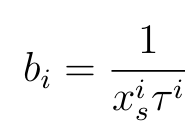

We refernece the TAP definition from the manual according to the Appendix B:
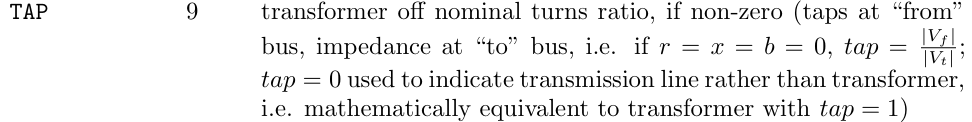

We note that in this case all branches have TAP=0:

In [41]:
br.TAP

branch
1     0.0
2     0.0
3     0.0
4     0.0
5     0.0
6     0.0
7     0.0
8     0.0
9     0.0
10    0.0
11    0.0
12    0.0
13    0.0
14    0.0
15    0.0
16    0.0
17    0.0
18    0.0
19    0.0
20    0.0
21    0.0
22    0.0
23    0.0
24    0.0
25    0.0
26    0.0
27    0.0
28    0.0
29    0.0
30    0.0
31    0.0
32    0.0
33    0.0
34    0.0
35    0.0
36    0.0
37    0.0
38    0.0
39    0.0
40    0.0
41    0.0
Name: TAP, dtype: float64

Hence, we calculate TAP and line susceptance accordingly:

In [42]:
tap = br.TAP.values.copy(); tap[tap == 0] = 1
b_line = 1 / (br.BR_X.values * tap)   

We now move to constructing admittance matrix. From the manual, the equations
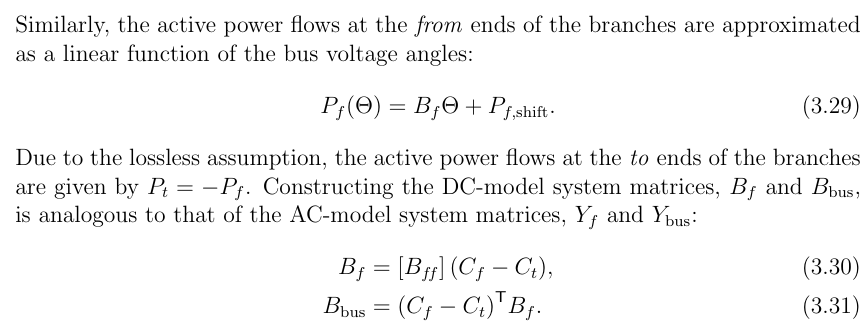

Note that the branch admittance matrix is also denoted in Section 3.2 in equation 3.3. The network equations are also in Section 3.4 

In [43]:
A = np.zeros((nl, nb))
# +1 at from-bus, -1 at to-bus
A[np.arange(nl), fb] = 1
A[np.arange(nl), tb] = -1

We note that we do not have the shift term from 3.29 as the TAP shift is 0 for all values:

In [44]:
br.SHIFT

branch
1     0.0
2     0.0
3     0.0
4     0.0
5     0.0
6     0.0
7     0.0
8     0.0
9     0.0
10    0.0
11    0.0
12    0.0
13    0.0
14    0.0
15    0.0
16    0.0
17    0.0
18    0.0
19    0.0
20    0.0
21    0.0
22    0.0
23    0.0
24    0.0
25    0.0
26    0.0
27    0.0
28    0.0
29    0.0
30    0.0
31    0.0
32    0.0
33    0.0
34    0.0
35    0.0
36    0.0
37    0.0
38    0.0
39    0.0
40    0.0
41    0.0
Name: SHIFT, dtype: float64

Hence, we can construct equation 3.31:

In [45]:
Bbus = A.T @ np.diag(b_line) @ A    # bus susceptance matrix

We now construct reactance matrix according to section 4.5:
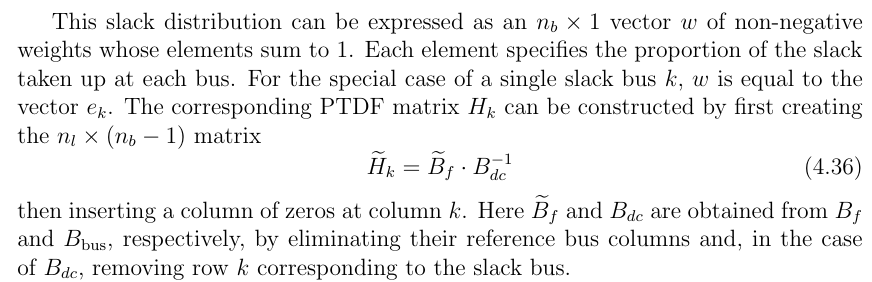


We eliminate the reference bus accordingly and invert the matrix:

In [46]:
X = np.zeros((nb, nb))
X[1:, 1:] = np.linalg.inv(Bbus[1:, 1:])          # drop the reference bus, invert
H = np.diag(b_line) @ A @ X                      # PTDF: flow = H @ net injection

For the final DC OPF formulation, we refer to https://arxiv.org/pdf/1811.00943. 

We refer to the following equations for forming the line constraints:
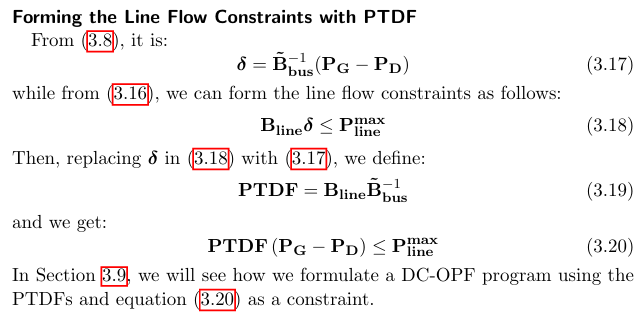

We refer to 3.9 for the OPF formulation:
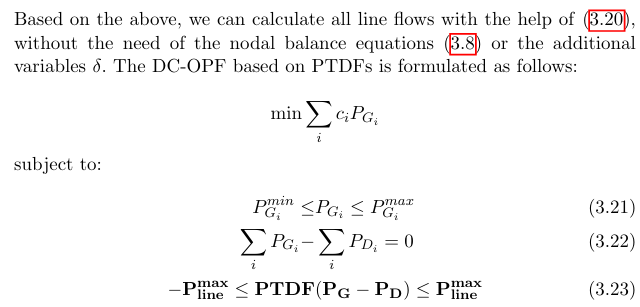

To implement the formulation, we adop the following simplications:
*   We linearize the quadratic cost functions to keep the problem LP to run the simulation in HiGHS
*   We scale the cost functions to be representative of the typical ISO prices
*   We create the profile for loads. We assume it to be identical across the system and is scaled to the maximum peak of the bus MW. 

The implementation of the assumptions is provided below. 

In [47]:
Cg = np.zeros((nb, ng)); Cg[gb, np.arange(ng)] = 1   # generator -> bus map

# quadratic cost c2 p^2 + c1 p + c0, cut into NSEG straight pieces such that the problem stays an LP
COST_SCALE = 15            # original costs 2–4 $/MWh -> translate to $30–60/MWh (assumption)
NSEG = 10
c2, c1, c0 = COST_SCALE * gc.iloc[:, 4:7].values.T
breaks = np.linspace(pmin, pmax, NSEG + 1).T     # breakpoints [gen, NSEG+1]
cost_at_breaks = c2[:, None] * breaks**2 + c1[:, None] * breaks + c0[:, None]
wid   = np.diff(breaks, axis=1)                  # MW width of each piece
slope = np.diff(cost_at_breaks, axis=1) / wid    # $/MWh of each piece (rising -> convex)

LOAD_SHAPE = np.array([.62,.58,.56,.55,.57,.63,.72,.82,.88,.92,.95,.97,
                       .98,.99,1.0,1.0,.99,.97,.95,.92,.87,.80,.72,.66])   # placeholder assumed load
Dgrid = LOAD_SHAPE[:, None] * pd0[None]          # MW [hour, bus]
PK = LOAD_SHAPE.argmax()                         # peak hour
T = 24

We formulate the optimization according to the equations above. The primary equation being (3.23), which implements the PTDF formulation. 

In [48]:

g    = cp.Variable((T, ng, NSEG), nonneg=True)   # MW used in each cost piece
Pg   = pmin + cp.sum(g, axis=2)                  # generator output [hour, gen]
inj  = Pg @ Cg.T - Dgrid                         # net injection per bus
flow = inj @ H.T                                 # line flows, equation (3.23)

balance = cp.sum(inj, axis=1) == 0               # system power balance  -> ν_ref 
line_up = flow <= RATE                           # line limits           -> κ+ (3.23)
line_lo = -flow <= RATE                          #                       -> κ- (3.23)
cost    = cp.sum(cp.multiply(g, slope[None]))

prob = cp.Problem(cp.Minimize(cost), [balance, line_up, line_lo, g <= wid[None]])
prob.solve(solver=cp.HIGHS)

nu_ref = -balance.dual_value                                            # $/MWh at the reference bus
LMP    = nu_ref[:, None] - (line_up.dual_value - line_lo.dual_value) @ H   # subtract congestion component
P_opf, F_opf = Pg.value, flow.value
assert nu_ref.mean() > 0, 'dual sign flipped'

print('reference price by hour:', nu_ref.round(1))
print('LMP spread by hour:', np.ptp(LMP, axis=1).round(2))      # should be 0 as no congestion without data centers
print('peak line loading (top 5):', np.sort(np.abs(F_opf[PK]) / RATE)[-5:].round(2))

C:\Users\16467\AppData\Local\Temp\ipykernel_46368\3963590539.py:12: UserWarning: The problem includes expressions that don't support CPP backend. Defaulting to the SCIPY backend for canonicalization.
  prob.solve(solver=cp.HIGHS)


reference price by hour: [41.5 39.8 39.8 39.8 39.8 41.5 44.6 46.6 47.8 48.3 50.  50.  50.  50.9
 50.9 50.9 50.9 50.  50.  48.3 47.8 46.4 44.6 41.5]
LMP spread by hour: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
peak line loading (top 5): [0.56 0.62 0.65 0.76 0.95]


### Verification

We verify and check our implementation with PyPSA (https://pypsa.org/). We compare the PTDF matrix as well as the resulting prices.

In [49]:

import pypsa
net = pypsa.Network(); net.set_snapshots(range(T))
buses = [f'b{i}' for i in range(nb)]
lines = [f'l{l}' for l in range(nl)]
loads = [f'd{i}' for i in range(nb)]

net.add('Bus', buses, v_nom=1.0)
net.add('Line', lines, bus0=[buses[i] for i in fb], bus1=[buses[j] for j in tb],
        x=br.BR_X.values * tap, r=0.0, s_nom=RATE)                 # same susceptance as H
net.add('Load', loads, bus=buses, p_set=pd.DataFrame(Dgrid, index=net.snapshots, columns=loads))
for i in range(ng):
    if pmin[i] > 0:                                                 # must-run block at Pmin
        net.add('Generator', f'g{i}_min', bus=buses[gb[i]], p_nom=pmin[i], p_min_pu=1.0)
    for j in range(NSEG):                                           # one generator per cost piece
        net.add('Generator', f'g{i}_{j}', bus=buses[gb[i]], p_nom=wid[i, j], marginal_cost=slope[i, j])
net.optimize(solver_name='highs')

# PTDF from PyPSA, re-referenced to the reference bus (row 0)
sn = net.sub_networks.obj.iloc[0]; sn.calculate_PTDF()
H_pypsa = pd.DataFrame(sn.PTDF, index=sn.branches_i().get_level_values(-1),
                       columns=sn.buses_o).loc[lines, buses].values
H_pypsa = H_pypsa - H_pypsa[:, [0]]

P_pypsa = np.column_stack([net.generators_t.p.filter(regex=rf'^g{i}_').sum(axis=1) for i in range(ng)])
print('max PTDF difference:        ', np.abs(H_pypsa - H).max().round(6))
print('max generator diff (MW):    ', np.abs(P_pypsa - P_opf).max().round(4))
print('max flow diff (MW):         ', np.abs(net.lines_t.p0[lines].values - F_opf).max().round(4))
print('max LMP diff ($/MWh):       ', np.abs(net.buses_t.marginal_price[buses].values - LMP).max().round(4))

C:\Users\16467\AppData\Local\Temp\ipykernel_46368\2741588188.py:16: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  net.optimize(solver_name='highs')
Index(['b0', 'b1', 'b2', 'b3', 'b4', 'b5', 'b6', 'b7', 'b8', 'b9', 'b10',
       'b11', 'b12', 'b13', 'b14', 'b15', 'b16', 'b17', 'b18', 'b19', 'b20',
       'b21', 'b22', 'b23', 'b24', 'b25', 'b26', 'b27', 'b28', 'b29'],
      dtype='object', name='name')
Index(['l0', 'l1', 'l2', 'l3', 'l4', 'l5', 'l6', 'l7', 'l8', 'l9', 'l10',
       'l11', 'l12', 'l13', 'l14', 'l15', 'l16', 'l17', 'l18', 'l19', 'l20',
       'l21', 'l22', 'l23', 'l24', 'l25', 'l26', 'l27', 'l28', 'l29', 'l30',
       'l31', 'l32', 'l33', 'l34', 'l35', 'l36', 'l37', 'l38', 'l39', 'l40'],
      dtype='object', name='name')
Index(['l0', '

max PTDF difference:         0.0
max generator diff (MW):     0.0
max flow diff (MW):          0.0
max LMP diff ($/MWh):        0.0


We save the resulting network to implement in the final optimization. We also define the sites where the Data Center load will be added. 

In [50]:
#save the grid for the PuttingTogether notebook
SITE_BUS = [3, 8, 21]                            # data center sites (bus numbers)
np.savez('ieee30_grid.npz', BUS_I=BUS_I, F_BUS=F_BUS, T_BUS=T_BUS, GEN_BUS=GEN_BUS,
         H=H, Cg=Cg, pmin=pmin, pmax=pmax, wid=wid, slope=slope, RATE=RATE,
         Dgrid=Dgrid, pd0=pd0, SITE_BUS=np.array(SITE_BUS))

Create a diagram of the network:

INFO:fontTools.subset:maxp pruned
INFO:fontTools.subset:LTSH dropped
INFO:fontTools.subset:cmap pruned
INFO:fontTools.subset:kern dropped
INFO:fontTools.subset:post pruned
INFO:fontTools.subset:PCLT dropped
INFO:fontTools.subset:JSTF dropped
INFO:fontTools.subset:meta dropped
INFO:fontTools.subset:GPOS pruned
INFO:fontTools.subset:GSUB pruned
INFO:fontTools.subset:glyf pruned
INFO:fontTools.subset:Added gid0 to subset
INFO:fontTools.subset:Added first four glyphs to subset
INFO:fontTools.subset:Closing glyph list over 'GSUB': 42 glyphs before
INFO:fontTools.subset:Glyph names: ['.notdef', 'B', 'D', 'G', 'L', 'M', 'T', 'W', 'a', 'c', 'd', 'e', 'eight', 'f', 'five', 'four', 'glyph00001', 'glyph00002', 'greaterequal', 'hyphen', 'i', 'k', 'l', 'm', 'n', 'nine', 'o', 'one', 'p', 'parenleft', 'parenright', 'percent', 'r', 's', 'seven', 'six', 'space', 't', 'three', 'two', 'u', 'zero']
INFO:fontTools.subset:Glyph IDs:   [0, 1, 2, 3, 8, 11, 12, 16, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 37, 3

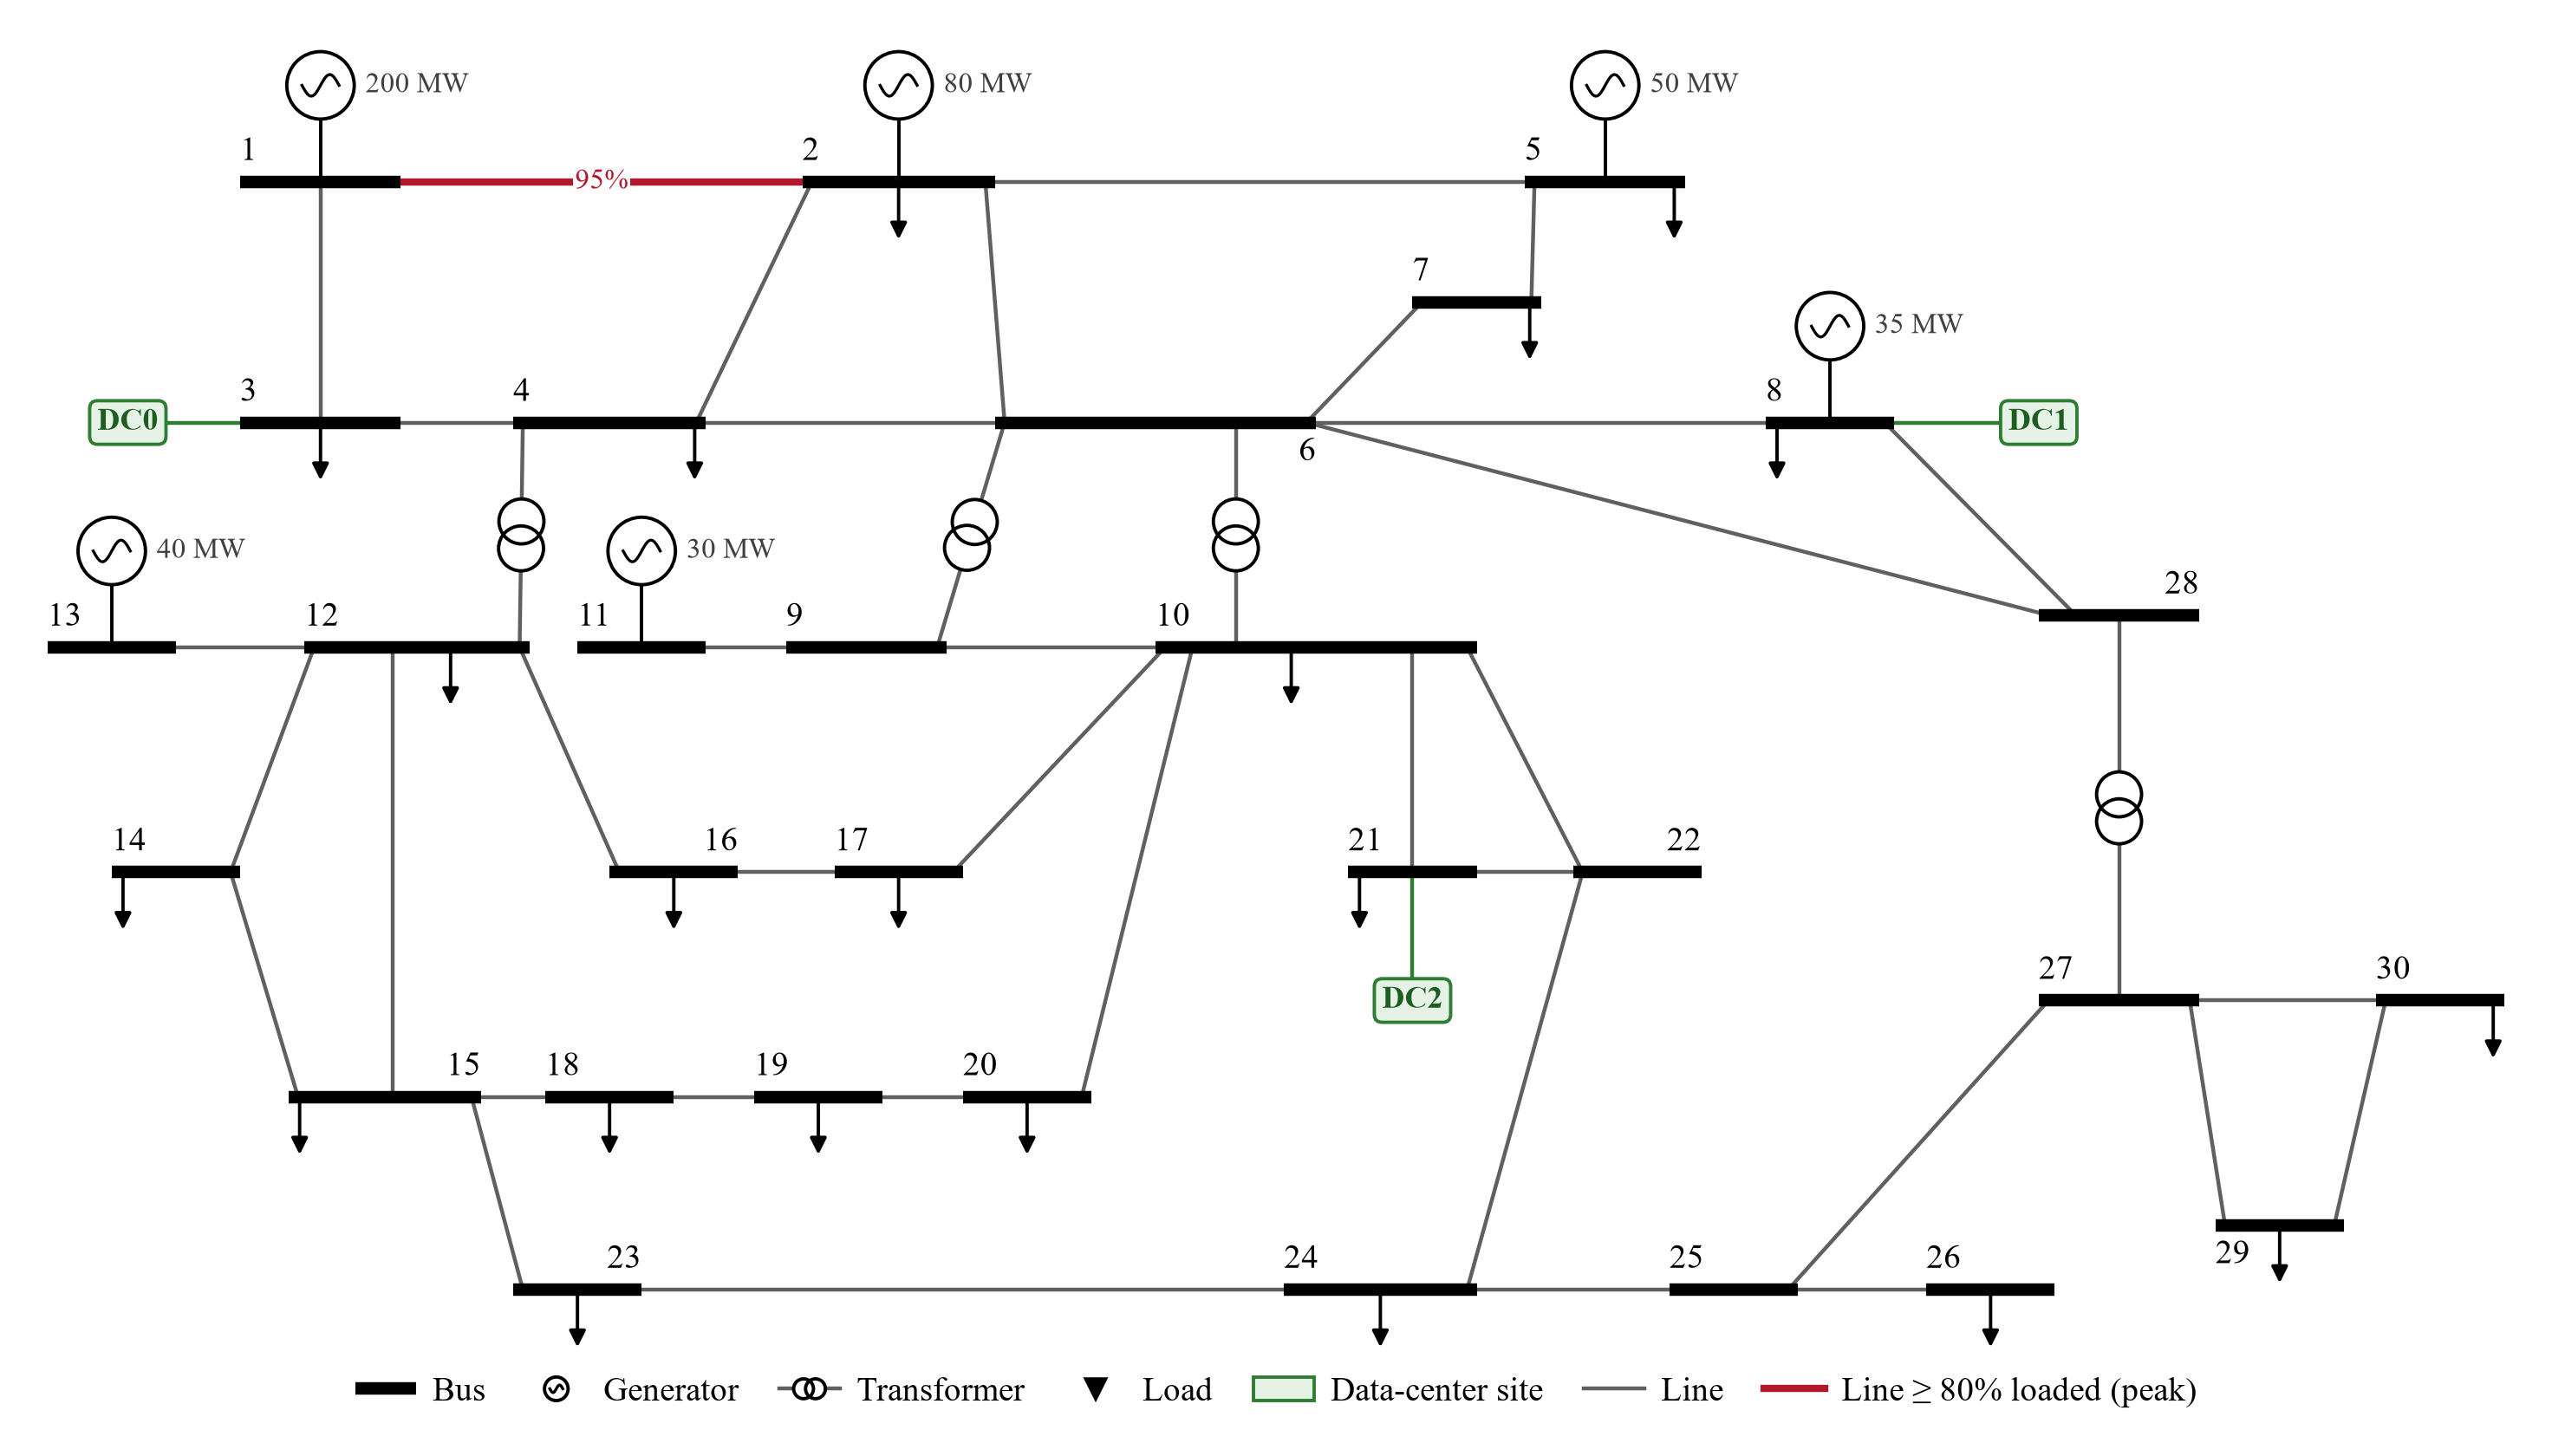

In [51]:
%config InlineBackend.figure_format = 'retina'
from collections import defaultdict
from matplotlib.patches import Circle, Patch
from matplotlib.lines import Line2D
from matplotlib.legend_handler import HandlerBase

# ---------------- style ----------------
FIG_W    = 7.16                    # inches: IEEE double column
FS_BUS   = 7.0                     # bus numbers / legend
FS_SMALL = 6.0                     # capacities, loadings, DC labels
LW_BUS, LW_LINE, LW_HOT = 2.6, 0.8, 1.5
INK, GREY, HOTC = 'k', '#606060', '#b2182b'
DC_FC, DC_EC, DC_TXT = '#e6f2e6', '#2e7d32', '#1b5e20'
HOT   = 0.8                        # highlight lines loaded at/above this share at peak
LEG_H = 0.28                       # inches reserved for the one-row legend
plt.rcParams.update({'font.family': 'serif',
                     'font.serif': ['Times New Roman', 'Times', 'Nimbus Roman', 'STIXGeneral', 'DejaVu Serif'],
                     'mathtext.fontset': 'stix', 'pdf.fonttype': 42, 'ps.fonttype': 42,
                     'figure.dpi': 200, 'savefig.dpi': 600})

# ---------------- layout (classic IEEE 30-bus arrangement, stretched horizontally) ----------------
POS = {1:(0.0, 4.5),   2:(3.6, 4.5),   5:(8.0, 4.5),
       7:(7.2, 3.75),
       3:(0.0, 3.0),   4:(1.8, 3.0),   6:(5.2, 3.0),   8:(9.4, 3.0),
       28:(11.2, 1.8),
       13:(-1.3, 1.6), 12:(0.6, 1.6),  11:(2.0, 1.6),  9:(3.4, 1.6),  10:(6.2, 1.6),
       14:(-0.9, 0.2), 16:(2.2, 0.2),  17:(3.6, 0.2),  21:(6.8, 0.2), 22:(8.2, 0.2),
       27:(11.2, -0.6), 30:(13.2, -0.6),
       15:(0.4, -1.2), 18:(1.8, -1.2), 19:(3.1, -1.2), 20:(4.4, -1.2),
       29:(12.2, -2.0),
       23:(1.6, -2.4), 24:(6.6, -2.4), 25:(8.8, -2.4), 26:(10.4, -2.4)}
H0   = 0.4                                             # default half-length of a bus bar
HALF = {1:.5, 2:.6, 3:.5, 4:.6, 5:.5, 6:1.0, 9:.5, 10:1.0, 12:.7, 15:.6, 24:.6, 27:.5, 28:.5}
GEN_DIR   = {}                                         # 'up' (default) / 'down' / 'left' / 'right'
DC_OFFSET = {3: (-1.2, 0.0), 8: (1.3, 0.0), 21: (0.0, -0.8)}    # data-center box offset from bus

DC_LABEL = [f'DC{s}' for s in range(len(SITE_BUS))]    # DC0, DC1, DC2, as in the paper

LABEL_FIX = {}                                         # force a bus-number spot, e.g. {6: 'br'}

# transformer branches of the original IEEE case (the AS data may carry no tap ratios)
XFMR = {(6, 9), (6, 10), (4, 12), (28, 27)}
XFMR |= {(f, t) for f, t, tp in zip(F_BUS, T_BUS, br.TAP.values) if tp not in (0, 1)}
XFMR = {frozenset(p) for p in XFMR}

def bar(b):
    x, y = POS[b]; h = HALF.get(b, H0)
    return x - h, x + h, y

_lo = min(bar(b)[0] for b in POS); _hi = max(bar(b)[1] for b in POS)
UPI = (_hi - _lo + 0.6) / FIG_W                        # data units per inch (for text-box sizing)

def text_rect(x, y, s, fs, ha, va):
    hgt = fs / 72 * UPI; wid = 0.55 * hgt * len(s)
    x0 = {'left': x, 'right': x - wid, 'center': x - wid / 2}[ha]
    y0 = {'bottom': y, 'top': y - hgt, 'center': y - hgt / 2}[va]
    return x0, y0, x0 + wid, y0 + hgt

obs = []                                               # sampled points of everything drawn
def add_seg(p, q, step=0.04):
    n = max(2, int(np.hypot(q[0] - p[0], q[1] - p[1]) / step) + 1)
    obs.append(np.linspace(p, q, n))
def add_rect(x0, y0, x1, y1, step=0.05):
    gx, gy = np.meshgrid(np.arange(x0, x1 + step, step), np.arange(y0, y1 + step, step))
    obs.append(np.column_stack([gx.ravel(), gy.ravel()]))

# ---------------- line end points: project onto bars, then spread so ends never coincide ----------------
ends, groups = {}, defaultdict(list)
for l in range(nl):
    a, b = F_BUS[l], T_BUS[l]
    (al, ah, ay), (bl, bh, by) = bar(a), bar(b)
    xa, xb = POS[a][0], POS[b][0]
    if abs(ay - by) < 1e-6:                            # same row: connect facing bar ends
        ends[l, 0], ends[l, 1] = (ah, bl) if xb > xa else (al, bh)
        continue
    lo, hi = max(al, bl), min(ah, bh)
    da, db = ((lo + hi) / 2,) * 2 if lo < hi else (np.clip(xb, al, ah), np.clip(xa, bl, bh))
    dy = abs(by - ay)
    groups[a, 'up' if by > ay else 'dn'].append((da, (xb - xa) / dy, l, 0))
    groups[b, 'up' if ay > by else 'dn'].append((db, (xa - xb) / dy, l, 1))

GAP, MARGIN = 0.17, 0.06
for (b, side), items in groups.items():
    lo, hi, _ = bar(b); lo += MARGIN; hi -= MARGIN
    items.sort(key=lambda t: (t[0], t[1]))             # by position, then fan direction (no crossings)
    p = np.clip([t[0] for t in items], lo, hi).astype(float)
    g = min(GAP, (hi - lo) / max(len(p) - 1, 1))
    for i in range(1, len(p)):            p[i] = max(p[i], p[i - 1] + g)
    p[-1] = min(p[-1], hi)
    for i in range(len(p) - 2, -1, -1):   p[i] = min(p[i], p[i + 1] - g)
    for (_, _, l, w), x in zip(items, p): ends[l, w] = x

# ---------------- draw ----------------
loading = np.abs(F_opf[PK]) / RATE                     # peak-hour loading, share of rating
fig, ax = plt.subplots(figsize=(FIG_W, 4))
seg = {}

for l in range(nl):                                    # lines
    p, q = (ends[l, 0], POS[F_BUS[l]][1]), (ends[l, 1], POS[T_BUS[l]][1])
    seg[l] = (p, q)
    hot = loading[l] >= HOT
    ax.plot(*zip(p, q), color=HOTC if hot else GREY, lw=LW_HOT if hot else LW_LINE,
            solid_capstyle='round', zorder=1)
    add_seg(p, q)

R_X = 0.14                                             # transformers: two interlocking circles
for l in range(nl):
    if frozenset((F_BUS[l], T_BUS[l])) not in XFMR: continue
    (x0, y0), (x1, y1) = seg[l]
    L = np.hypot(x1 - x0, y1 - y0); ux, uy = (x1 - x0) / L, (y1 - y0) / L
    cx, cy = (x0 + x1) / 2, (y0 + y1) / 2
    centers = [(cx + s * 0.6 * R_X * ux, cy + s * 0.6 * R_X * uy) for s in (-1, 1)]
    for c in centers: ax.add_patch(Circle(c, R_X, fc='white', ec='none', zorder=3))
    for c in centers: ax.add_patch(Circle(c, R_X, fc='none', ec=INK, lw=0.7, zorder=4))
    add_rect(cx - 1.6 * R_X, cy - 1.6 * R_X, cx + 1.6 * R_X, cy + 1.6 * R_X)

for b in BUS_I:                                        # bus bars
    lo, hi, y = bar(b)
    ax.plot([lo, hi], [y, y], color=INK, lw=LW_BUS, solid_capstyle='butt', zorder=5)
    add_seg((lo, y), (hi, y))

R_G, DY_G = 0.21, 0.6                                  # generators: circle with a sine wave
for b in np.unique(GEN_BUS):
    x, y = POS[b]; h = HALF.get(b, H0); cap = pmax[GEN_BUS == b].sum()
    d = GEN_DIR.get(b, 'up')
    if   d == 'up':    gx, gy = x, y + DY_G;     stub = ((x, y), (x, gy - R_G))
    elif d == 'down':  gx, gy = x, y - DY_G;     stub = ((x, y), (x, gy + R_G))
    elif d == 'left':  gx, gy = x - h - DY_G, y; stub = ((x - h, y), (gx + R_G, y))
    else:              gx, gy = x + h + DY_G, y; stub = ((x + h, y), (gx - R_G, y))
    ax.plot(*zip(*stub), color=INK, lw=0.7, zorder=4); add_seg(*stub)
    ax.add_patch(Circle((gx, gy), R_G, fc='white', ec=INK, lw=0.7, zorder=6))
    t = np.linspace(-1, 1, 40)
    ax.plot(gx + 0.55 * R_G * t, gy + 0.32 * R_G * np.sin(np.pi * t), color=INK, lw=0.6, zorder=7)
    add_rect(gx - R_G, gy - R_G, gx + R_G, gy + R_G)
    s = f'{cap:.0f} MW'
    ax.text(gx + R_G + 0.07, gy, s, fontsize=FS_SMALL, color='#404040', ha='left', va='center', zorder=7)
    add_rect(*text_rect(gx + R_G + 0.07, gy, s, FS_SMALL, 'left', 'center'))

dc_down = defaultdict(list)                            # data-center sites
for s, b in enumerate(SITE_BUS):
    x, y = POS[b]; lo, hi, _ = bar(b); h = HALF.get(b, H0)
    dx, dy = DC_OFFSET.get(b, (0.0, -0.7))
    bx, by = x + dx, y + dy
    sx = hi if dx > h else lo if dx < -h else bx
    ax.plot([sx, bx], [y, by], color=DC_EC, lw=0.8, zorder=2); add_seg((sx, y), (bx, by))
    ax.text(bx, by, DC_LABEL[s], ha='center', va='center', fontsize=FS_SMALL + 0.5, color=DC_TXT,
            fontweight='bold', zorder=8,
            bbox=dict(boxstyle='round,pad=0.25', fc=DC_FC, ec=DC_EC, lw=0.7))
    x0, y0, x1, y1 = text_rect(bx, by, DC_LABEL[s], FS_SMALL + 0.5, 'center', 'center')
    add_rect(x0 - 0.1, y0 - 0.1, x1 + 0.1, y1 + 0.1)
    if dy < 0: dc_down[b].append(sx)

LOAD_LEN = 0.36                                        # loads: arrow below the bar, at the freest spot
for i, b in enumerate(BUS_I):
    if pd0[i] <= 0: continue
    lo, hi, y = bar(b); x = POS[b][0]
    taken = [ends[l, w] for _, _, l, w in groups.get((b, 'dn'), [])] + dc_down[b]
    cand = np.linspace(lo + 0.07, hi - 0.07, 13)
    score = [min([abs(c - t) for t in taken], default=9.0) - 0.02 * abs(c - x) for c in cand]
    c = cand[int(np.argmax(score))]
    ax.annotate('', xy=(c, y - LOAD_LEN), xytext=(c, y), zorder=4,
                arrowprops=dict(arrowstyle='-|>', mutation_scale=7, lw=0.7, color=INK, shrinkA=0, shrinkB=0))
    add_seg((c, y), (c, y - LOAD_LEN))

for l in range(nl):                                    # loading labels on hot lines
    if loading[l] < HOT: continue
    (x0, y0), (x1, y1) = seg[l]
    t = 0.27 if frozenset((F_BUS[l], T_BUS[l])) in XFMR else 0.5
    tx, ty = x0 + t * (x1 - x0), y0 + t * (y1 - y0)
    s = f'{loading[l]:.0%}'
    ax.text(tx, ty, s, fontsize=FS_SMALL, color=HOTC, ha='center', va='center', zorder=9,
            bbox=dict(fc='white', ec='none', pad=0.4))
    add_rect(*text_rect(tx, ty, s, FS_SMALL, 'center', 'center'))

D, PREF = 0.09, ['al', 'ar', 'bl', 'br', 'l', 'r']    # bus numbers: least-cluttered of six spots
for b in BUS_I:
    lo, hi, y = bar(b); s = str(b)
    opts = {'al': (lo, y + D, 'left', 'bottom'), 'ar': (hi, y + D, 'right', 'bottom'),
            'bl': (lo, y - D, 'left', 'top'),    'br': (hi, y - D, 'right', 'top'),
            'l':  (lo - D, y, 'right', 'center'), 'r': (hi + D, y, 'left', 'center')}
    P = np.vstack(obs)
    def hits(k):
        x0, y0, x1, y1 = text_rect(opts[k][0], opts[k][1], s, FS_BUS, opts[k][2], opts[k][3])
        return np.sum((P[:, 0] > x0 - .03) & (P[:, 0] < x1 + .03) & (P[:, 1] > y0 - .03) & (P[:, 1] < y1 + .03))
    k = LABEL_FIX.get(b) or min(PREF, key=lambda k: (hits(k), PREF.index(k)))
    x, yy, ha, va = opts[k]
    ax.text(x, yy, s, fontsize=FS_BUS, ha=ha, va=va, zorder=9)
    add_rect(*text_rect(x, yy, s, FS_BUS, ha, va))

# ---------------- legend (one row) ----------------
class _Gen: pass
class _Xf:  pass
class HGen(HandlerBase):
    def create_artists(self, legend, orig, x0, y0, w, h, fs, trans):
        r, cx, cy = 0.5 * h, x0 + w / 2, y0 + h / 2; t = np.linspace(-1, 1, 30)
        return [Circle((cx, cy), r, fc='white', ec=INK, lw=0.7, transform=trans),
                Line2D(cx + 0.55 * r * t, cy + 0.32 * r * np.sin(np.pi * t), color=INK, lw=0.6, transform=trans)]
class HXf(HandlerBase):
    def create_artists(self, legend, orig, x0, y0, w, h, fs, trans):
        r, cx, cy = 0.42 * h, x0 + w / 2, y0 + h / 2
        out = [Line2D([x0, x0 + w], [cy, cy], color=GREY, lw=LW_LINE, transform=trans)]
        out += [Circle((cx + s * 0.6 * r, cy), r, fc='white', ec='none', transform=trans) for s in (-1, 1)]
        out += [Circle((cx + s * 0.6 * r, cy), r, fc='none', ec=INK, lw=0.7, transform=trans) for s in (-1, 1)]
        return out

handles = [Line2D([], [], color=INK, lw=LW_BUS, solid_capstyle='butt'), _Gen(), _Xf(),
           Line2D([], [], marker='v', ls='', color=INK, ms=3.5),
           Patch(fc=DC_FC, ec=DC_EC, lw=0.7),
           Line2D([], [], color=GREY, lw=LW_LINE), Line2D([], [], color=HOTC, lw=LW_HOT)]
labels = ['Bus', 'Generator', 'Transformer', 'Load', 'Data-center site', 'Line',
          f'Line ≥ {HOT:.0%} loaded (peak)']
ax.legend(handles, labels, handler_map={_Gen: HGen(), _Xf: HXf()}, loc='upper center',
          bbox_to_anchor=(0.5, 0.0), ncol=len(labels), frameon=False, fontsize=FS_BUS,
          handlelength=1.8, handletextpad=0.5, columnspacing=1.2, borderaxespad=0.1)

# ---------------- frame to content, size the figure ----------------
P = np.vstack(obs); m = 0.08
x0, x1 = P[:, 0].min() - m, P[:, 0].max() + m
y0, y1 = P[:, 1].min() - m, P[:, 1].max() + m
ax.set_xlim(x0, x1); ax.set_ylim(y0, y1); ax.set_aspect('equal'); ax.axis('off')
H = FIG_W * (y1 - y0) / (x1 - x0) + LEG_H
fig.set_size_inches(FIG_W, H); ax.set_position([0, LEG_H / H, 1, 1 - LEG_H / H])
plt.savefig('fig_ieee30.pdf', bbox_inches='tight', pad_inches=0.01)            # vector, for LaTeX
plt.savefig('fig_ieee30.png', bbox_inches='tight', pad_inches=0.01, dpi=600)   # raster, for slides/Word
plt.show()

### Acknowledgements

The authors disclose the use of Anthropic Claude to conduct this work. The usage included assistance in writing, literature review, methodology refinement, and code generation and editing. Conceptual ideas, experimental design, implementations, analyses, and conclusions are the authors’ own. The authors take responsibility for all mistakes.